# Filter pipeline walkthrough: ED → DMRG → MPS-to-circuit → dyadic filter → AA → QETU

Self-contained (numpy, scipy, quimb; qiskit optional for the KAK CNOT count). Small N, exact statevectors.

* **Model.** Open dimerised $J_1$-$J_2$ chain $H = J_1\sum_i (1+(-1)^i\delta)\,\mathbf S_i\cdot\mathbf S_{i+1} + J_2\sum_i \mathbf S_i\cdot\mathbf S_{i+2}$.
* **Filter variable.** $H_s = (H-E_0)/W$, $W = E_{\max}-E_0$, relative gap $\eta = \Delta/W$, $\tau = \pi/(1+\eta)$.
* **Dyadic filter.** $F(H_s) = \prod_{k<K}\cos(2^k\tau H_s)^r$, one ancilla-controlled pulse per factor.
* **Time evolution is exact here** (matrix exponentials, no Trotter), so the filter is isolated from Trotter error. Costs are given as calls to the controlled unit $e^{-i\tau H_s Z_a}$.

In [1]:
# ---- parameters (edit here) ----
N       = 8         # spins (even)
J1, J2  = 1.0, 0.2411
DELTA   = 0.15      # dimerisation: gap knob
GAMMA   = 0.2       # target overlap of the trial with the ground state: overlap knob
EPS     = 1e-2      # target infidelity 1 - F after the filter
TRIAL   = "mps1"    # workflow trial: "mps1" = staggered Rz on the 1-layer MPS-to-circuit state; "rz" = on the exact
                    # ground state (the gap-vs-overlap study in section 8 always uses exact + Rz)

import numpy as np, scipy.linalg as sla
from functools import reduce
from scipy.optimize import brentq, least_squares
np.set_printoptions(precision=6, suppress=True)
I2, X, Y, Z = np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1., -1.])

## 1. Hamiltonian and exact diagonalisation

In [2]:
def op(P, i):                                     # Pauli P on site i (site 0 = most significant bit)
    return reduce(np.kron, [P if k == i else I2 for k in range(N)])

def bonds(delta):
    b = [(i, i + 1, J1 * (1 + (-1) ** i * delta)) for i in range(N - 1)]
    return b + [(i, i + 2, J2) for i in range(N - 2)]

def hamiltonian(delta):                           # S.S = (XX + YY + ZZ) / 4
    return sum(J / 4 * (op(P, i) @ op(P, j)).real for i, j, J in bonds(delta) for P in (X, Y, Z))   # YY is real

def spectrum(delta):
    E, V = np.linalg.eigh(hamiltonian(delta))
    return E, V

Sz_tot = sum(op(Z, i) for i in range(N)).real / 2
print(f"N = {N}, J1 = {J1}, J2 = {J2}")
print(f"{'delta':>7} {'E0':>10} {'gap Δ':>8} {'W':>8} {'η = Δ/W':>9}")
for d in (-0.2, -0.1, 0.0, 0.1, DELTA, 0.3, 0.6):
    E, _ = spectrum(d)
    print(f"{d:7.3f} {E[0]:10.5f} {E[1] - E[0]:8.4f} {E[-1] - E[0]:8.4f} {(E[1] - E[0]) / (E[-1] - E[0]):9.5f}"
          + ("   <- chosen" if d == DELTA else ""))

H = hamiltonian(DELTA)
E, V = np.linalg.eigh(H)
E0, E1, Emax = E[0], E[1], E[-1]
g0 = V[:, 0]
Delta, W = E1 - E0, Emax - E0
eta, tau = Delta / W, np.pi / (1 + Delta / W)
deg = np.sum(abs(E - E1) < 1e-9)
print(f"\nchosen delta = {DELTA}:  E0 = {E0:.8f}, E1 = {E1:.8f} ({deg}-fold, triplet), Emax = {Emax:.6f}")
print(f"gap Δ = {Delta:.6f},  W = {W:.6f},  η = Δ/W = {eta:.6f},  τ = π/(1+η) = {tau:.6f}")
print(f"<S^z_tot> of ground state = {g0 @ Sz_tot @ g0:.1e}  (singlet, S^z = 0 sector)")

N = 8, J1 = 1.0, J2 = 0.2411
  delta         E0    gap Δ        W   η = Δ/W
 -0.200   -2.93313   0.0448   4.9948   0.00896
 -0.100   -2.96567   0.1730   5.0523   0.03424


  0.000   -3.13500   0.3859   5.2467   0.07355
  0.100   -3.36959   0.6146   5.5062   0.11162
  0.150   -3.49903   0.7256   5.6482   0.12846   <- chosen


  0.300   -3.91361   1.0378   6.1003   0.17013
  0.600   -4.80138   1.5641   7.0630   0.22145



chosen delta = 0.15:  E0 = -3.49903410, E1 = -2.77345583 (3-fold, triplet), Emax = 2.149150
gap Δ = 0.725578,  W = 5.648184,  η = Δ/W = 0.128462,  τ = π/(1+η) = 2.783959
<S^z_tot> of ground state = 2.6e-29  (singlet, S^z = 0 sector)


## 2. DMRG on the same Hamiltonian, spectral errors vs ED, and the 1-layer MPS-to-circuit trial

* DMRG gives $E_0$; $E_{\max}$ from DMRG on $-H$; $E_1$ from DMRG with a penalty $\lambda(S^z_{tot}-1)^2$ (lowest triplet).
* MPS-to-circuit: [qiskit-community/mps-to-circuit](https://github.com/qiskit-community/mps-to-circuit), approximate method with one layer
  (truncate to bond dimension 2, one staircase of $N-1$ two-qubit gates on $|0\cdots0\rangle$). Its overlap with the ED ground state is $\gamma_0$.
  Install: `pip install --ignore-requires-python mps-to-circuit`.

In [3]:
import quimb.operator as qop, quimb.tensor as qtn

def builder(sign=1.0, penalty=None):
    Jd = {(i, j): sign * J for i, j, J in bonds(DELTA)}
    b = qop.heisenberg_from_edges(list(Jd), j=lambda i, j: Jd[(i, j)] if (i, j) in Jd else Jd[(j, i)])
    if penalty:                                   # lam (Sz - 1)^2 = lam [sum_{i!=j} sz_i sz_j - 2 Sz] + lam (N/4 + 1)
        for i in range(N):
            for j in range(N):
                if i != j:
                    b.add_term(penalty, ("sz", i), ("sz", j))
            b.add_term(-2 * penalty, ("sz", i))
    return b.build_mpo()

def dmrg(mpo):
    d = qtn.DMRG2(mpo, bond_dims=[16, 32, 64], cutoffs=1e-12)
    d.solve(tol=1e-10, verbosity=0, max_sweeps=40)
    return float(np.real(d.energy)), d.state

E0_d, psi_d = dmrg(builder())
Emax_d = -dmrg(builder(-1.0))[0]
lam = 2.0
E1_d = dmrg(builder(penalty=lam))[0] + lam * (N / 4 + 1)
g0_d = psi_d.to_dense().ravel(); g0_d /= np.linalg.norm(g0_d)
print(f"{'':6} {'ED':>14} {'DMRG':>14} {'error':>10}")
for name, a, b in (("E0", E0, E0_d), ("E1", E1, E1_d), ("Emax", Emax, Emax_d),
                   ("Δ", Delta, E1_d - E0_d), ("η", eta, (E1_d - E0_d) / (Emax_d - E0_d))):
    print(f"{name:6} {a:14.9f} {b:14.9f} {b - a:10.1e}")
print(f"ground state infidelity 1 - |<ED|DMRG>|^2 = {1 - abs(np.vdot(g0, g0_d)) ** 2:.1e}, max bond {psi_d.max_bond()}")

# ---- 1-layer MPS-to-circuit with qiskit-community/mps-to-circuit (Ran 2020, one layer of two-qubit gates)
# install: pip install --ignore-requires-python git+https://github.com/qiskit-community/mps-to-circuit
from mps_to_circuit import mps_to_circuit
from qiskit.quantum_info import Statevector, Operator
from qiskit.circuit.library import CXGate
from qiskit.synthesis import TwoQubitBasisDecomposer

mps = psi_d.copy(); mps.permute_arrays("lrp")                      # tensor index order (left, right, physical)
qc_prep = mps_to_circuit(list(mps.arrays), method="approximate", shape="lrp", num_layers=1)
sv = Statevector(qc_prep).data                                       # qiskit: qubit i = site i, little-endian
psi_mps1 = sv.reshape([2] * N).transpose(range(N - 1, -1, -1)).ravel()   # -> site 0 = most significant bit
gamma0 = abs(np.vdot(g0, psi_mps1)) ** 2
kak = TwoQubitBasisDecomposer(CXGate())
two_q = [i for i in qc_prep.data if len(i.qubits) == 2]
cnots = sum(int(kak.num_basis_gates(Operator(i.operation).data)) for i in two_q)
print(f"\n1-layer MPS-to-circuit (mps-to-circuit, approximate, 1 layer): {len(two_q)} two-qubit gates, {cnots} CNOTs (KAK)")
print(f"  <S^z_tot> = {np.vdot(psi_mps1, Sz_tot @ psi_mps1).real:.1e},  overlap with ED ground state γ0 = {gamma0:.6f}")

                   ED           DMRG      error
E0       -3.499034099   -3.499034099   -4.9e-15
E1       -2.773455831   -2.773455831    9.8e-15
Emax      2.149150000    2.149150000   -4.4e-15
Δ         0.725578269    0.725578269    1.5e-14
η         0.128462220    0.128462220    2.6e-15
ground state infidelity 1 - |<ED|DMRG>|^2 = -4.4e-16, max bond 16



1-layer MPS-to-circuit (mps-to-circuit, approximate, 1 layer): 7 two-qubit gates, 19 CNOTs (KAK)
  <S^z_tot> = 1.6e-08,  overlap with ED ground state γ0 = 0.977907


## 3. Trial state and the dyadic filter (repeat until success, N + 1 qubits)

Trial: $e^{-i\epsilon\sum_i(-1)^iZ_i}$ on the base state, with $\epsilon$ solved so $|\langle E_0|\text{trial}\rangle|^2 = \gamma$.
Each pulse: H on the ancilla, $e^{-i\,2^k\tau H_s Z_a}$, H, measure the ancilla; outcome 0 applies $\cos(2^k\tau H_s)$.
The cheapest $(K, r)$ reaching $1-F\le\epsilon$ is picked from the exact filter function, then the ancilla circuit is run.

In [4]:
Hs_E = (E - E0) / W                                     # eigenvalues of H_s
def evolve(t, v):                                       # e^{-i t H_s} v, exact (v may carry leading batch axes)
    return ((v @ V.conj()) * np.exp(-1j * t * Hs_E)) @ V.T

stag = np.array([sum((-1) ** i * (1 - 2 * ((b >> (N - 1 - i)) & 1)) for i in range(N)) for b in range(2 ** N)])
base = g0 if TRIAL == "rz" else psi_mps1
trial_of = lambda e: np.exp(-1j * e * stag) * base
ov = lambda e: abs(np.vdot(g0, trial_of(e))) ** 2
es = np.linspace(0, 1.5, 301); first_min = es[np.argmax(np.diff([ov(e) for e in es]) > 0)]
eps_knob = brentq(lambda e: ov(e) - GAMMA, 0, first_min)
trial = trial_of(eps_knob)
print(f"trial: {TRIAL}, Rz angle ε_knob = {eps_knob:.6f}, overlap γ = {ov(eps_knob):.6f}")

def filter_fn(x, K, r):                                 # F on eigenvalues of H_s
    return np.prod([np.cos(2 ** k * tau * x) for k in range(K)], axis=0) ** r

c = V.conj().T @ trial                                  # trial in the eigenbasis
def p_and_infid(K, r):
    f = filter_fn(Hs_E, K, r); p = np.sum(abs(c * f) ** 2)
    return p, 1 - abs(c[0] * f[0]) ** 2 / p

best = min(((r * (2 ** K - 1) / p_and_infid(K, r)[0], K, r) for K in range(1, 14) for r in range(1, 10)
            if p_and_infid(K, r)[1] <= EPS), default=None)
assert best, "no (K, r) reaches EPS"
_, K, r = best
print(f"cheapest dyadic filter for 1-F <= {EPS}: K = {K}, r = {r}  ->  {K * r} pulses, "
      f"d = r(2^K-1) = {r * (2 ** K - 1)} calls of e^(-iτ H_s Z_a)")

# ---- run it as a circuit: one ancilla, measured and reset after every pulse
psi, p_tot = trial.copy(), 1.0
print(f"\n{'pulse':>5} {'k':>2} {'P(anc = 0)':>11} {'1 - F so far':>13}")
for j, k in enumerate([k for _ in range(r) for k in range(K)]):
    a0, a1 = psi / np.sqrt(2), psi / np.sqrt(2)                       # H on |0>_a
    a0, a1 = evolve(2 ** k * tau, a0), evolve(-(2 ** k) * tau, a1)   # e^{-i 2^k τ H_s Z_a}
    out0 = (a0 + a1) / np.sqrt(2)                                     # H, keep ancilla = 0
    pk = np.vdot(out0, out0).real; p_tot *= pk; psi = out0 / np.sqrt(pk)
    print(f"{j + 1:5d} {k:2d} {pk:11.6f} {1 - abs(np.vdot(g0, psi)) ** 2:13.3e}")
p_rus, inf_rus = p_and_infid(K, r)
print(f"\nRUS: success p = {p_tot:.6f} (formula {p_rus:.6f}),  1 - F = {1 - abs(np.vdot(g0, psi)) ** 2:.3e}")
print(f"cost per success = d/p = {r * (2 ** K - 1) / p_tot:.1f} controlled-τ calls,  qubits N + 1 = {N + 1}")

trial: mps1, Rz angle ε_knob = 0.283216, overlap γ = 0.200000
cheapest dyadic filter for 1-F <= 0.01: K = 3, r = 2  ->  6 pulses, d = r(2^K-1) = 14 calls of e^(-iτ H_s Z_a)

pulse  k  P(anc = 0)  1 - F so far
    1  0    0.612928     6.737e-01
    2  1    0.595337     4.519e-01
    3  2    0.580771     5.626e-02
    4  0    0.974719     3.178e-02
    5  1    0.977532     9.527e-03
    6  2    0.992011     1.551e-03

RUS: success p = 0.200311 (formula 0.200311),  1 - F = 1.551e-03
cost per success = d/p = 69.9 controlled-τ calls,  qubits N + 1 = 9


### 3b. Spectral weight of the trial states

How the population is spread over the eigenlevels of $H$ (weight summed over each degenerate multiplet, labelled by total spin $S$): the 1-layer MPS-to-circuit state, the exact ground state + staggered Rz, and MPS-to-circuit + staggered Rz, both at the target γ. The staggered Rz conserves $S^z$ but breaks SU(2), so it moves weight into $S \geq 1$ levels, including the lowest triplet at $E_s = \eta$.

70 distinct levels (multiplets) in the full 2^8 space; η = 0.1285

MPS-to-circuit (no Rz):  overlap with ground state = 0.9779
   levels holding > 1e-2: 2,  > 1e-3: 7,  > 1e-4: 14;  levels for 99% of the weight: 3,  for 99.9%: 11
    E_s = (E-E0)/W    S  deg     weight
           0.00000  0.0    1   9.78e-01
           0.22693  0.0    1   1.10e-02
           0.33750  0.0    1   2.41e-03
           0.37775  1.0    3   1.69e-03
           0.48179  2.0    5   1.30e-03
           0.43813  1.0    3   1.27e-03
           0.12846  1.0    3   1.16e-03
           0.29467  0.0    1   8.90e-04
   weight by total spin S: S=0: 9.927e-01, S=1: 5.481e-03, S=2: 1.839e-03, S=3: 3.806e-06, S=4: 1.364e-07

exact + Rz (γ = 0.2):  overlap with ground state = 0.2000
   levels holding > 1e-2: 13,  > 1e-3: 30,  > 1e-4: 40;  levels for 99% of the weight: 27,  for 99.9%: 37
    E_s = (E-E0)/W    S  deg     weight
           0.12846  1.0    3   3.24e-01
           0.00000  0.0    1   2.00e-01
           0.34173 

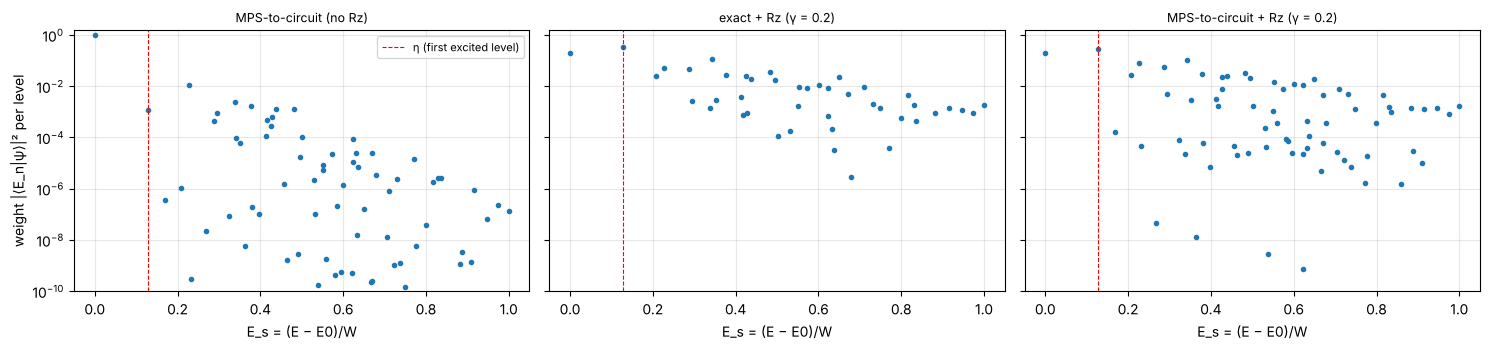

In [5]:
import matplotlib.pyplot as plt
# ---- where does the trial's weight sit? |<E_n|psi>|^2 summed over each degenerate level, labelled by total spin S
Sx_t, Sy_t = sum(op(X, i) for i in range(N)) / 2, sum(op(Y, i) for i in range(N)) / 2
S2 = (Sx_t @ Sx_t + Sy_t @ Sy_t + Sz_tot @ Sz_tot).real
lev_start = np.flatnonzero(np.r_[True, np.diff(E) > 1e-8])          # first eigenvector index of each level
lev_end = np.r_[lev_start[1:], len(E)]
S_lev = [max(0.0, 0.5 * (-1 + np.sqrt(1 + 4 * np.trace(V[:, a:b].T @ S2 @ V[:, a:b]) / (b - a)))) for a, b in zip(lev_start, lev_end)]

def rz_stag(v, e):                                                  # exp(-i e sum_i (-1)^i Z_i) v
    return np.exp(-1j * e * stag) * v
def eps_for(v, gamma):
    f = lambda e: abs(np.vdot(g0, rz_stag(v, e))) ** 2
    es = np.linspace(0, 1.5, 301); top = es[np.argmax(np.diff([f(e) for e in es]) > 0)]
    return brentq(lambda e: f(e) - gamma, 0, top) if f(top) <= gamma <= f(0) else None

def level_weights(v):
    c2 = abs(V.conj().T @ v) ** 2
    return np.array([c2[a:b].sum() for a, b in zip(lev_start, lev_end)])

states = {"MPS-to-circuit (no Rz)": psi_mps1}
e_ex, e_m1 = eps_for(g0, GAMMA), eps_for(psi_mps1, GAMMA)
if e_ex is not None: states[f"exact + Rz (γ = {GAMMA})"] = rz_stag(g0, e_ex)
if e_m1 is not None: states[f"MPS-to-circuit + Rz (γ = {GAMMA})"] = rz_stag(psi_mps1, e_m1)

fig, ax = plt.subplots(1, len(states), figsize=(5 * len(states), 3.6), sharey=True)
print(f"{len(lev_start)} distinct levels (multiplets) in the full 2^{N} space; η = {eta:.4f}\n")
for a_, (name, v) in zip(np.atleast_1d(ax), states.items()):
    w = level_weights(v); order = np.argsort(w)[::-1]; cum = np.cumsum(w[order])
    print(f"{name}:  overlap with ground state = {w[0]:.4f}")
    print(f"   levels holding > 1e-2: {np.sum(w > 1e-2)},  > 1e-3: {np.sum(w > 1e-3)},  > 1e-4: {np.sum(w > 1e-4)};"
          f"  levels for 99% of the weight: {np.searchsorted(cum, 0.99) + 1},  for 99.9%: {np.searchsorted(cum, 0.999) + 1}")
    print(f"   {'E_s = (E-E0)/W':>15} {'S':>4} {'deg':>4} {'weight':>10}")
    for j in order[:8]:
        print(f"   {(E[lev_start[j]] - E0) / W:15.5f} {S_lev[j]:4.1f} {lev_end[j] - lev_start[j]:4d} {w[j]:10.2e}")
    by_S = {}
    for j in range(len(w)):
        by_S[round(S_lev[j])] = by_S.get(round(S_lev[j]), 0) + w[j]
    print("   weight by total spin S: " + ", ".join(f"S={s}: {x:.3e}" for s, x in sorted(by_S.items()) if x > 1e-12) + "\n")
    Es = (E[lev_start] - E0) / W
    a_.semilogy(Es[w > 1e-12], w[w > 1e-12], "o", ms=3)
    a_.axvline(eta, color="r", lw=0.8, ls="--", label="η (first excited level)")
    a_.set_xlabel("E_s = (E − E0)/W"); a_.set_title(name, fontsize=9); a_.grid(alpha=0.3); a_.set_ylim(1e-10, 1.5)
np.atleast_1d(ax)[0].set_ylabel("weight |⟨E_n|ψ⟩|² per level"); np.atleast_1d(ax)[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. Amplitude amplification on the dyadic filter (N + K·r qubits)

No mid-circuit measurement, so each pulse gets its own ancilla. $A$ = all pulses on $|\text{trial}\rangle|0\cdots0\rangle$;
one round $Q = -A\,R_0\,A^\dagger R_{good}$ with $R_{good}$ = sign flip of "all ancillas 0" and $A R_0 A^\dagger$ = reflection about the
start state. $k = \text{round}(\pi/4\theta - 1/2)$, $\sin\theta = \sqrt p$.

In [6]:
m = K * r
ks = [k for _ in range(r) for k in range(K)]
def apply_pulses(st, dagger=False):                      # st: shape (2,)*m + (2^N,)
    for j in (reversed(range(m)) if dagger else range(m)):
        st = np.moveaxis(st, j, 0)
        a0, a1 = (st[0] + st[1]) / np.sqrt(2), (st[0] - st[1]) / np.sqrt(2)     # H
        t = 2 ** ks[j] * tau * (-1 if dagger else 1)
        a0, a1 = evolve(t, a0), evolve(-t, a1)
        st = np.moveaxis(np.stack([(a0 + a1) / np.sqrt(2), (a0 - a1) / np.sqrt(2)]), 0, j)
    return st

start = np.zeros((2,) * m + (2 ** N,), complex); start[(0,) * m] = trial
st = apply_pulses(start)
theta = np.arcsin(np.sqrt(p_rus)); k_aa = int(round(np.pi / (4 * theta) - 0.5))
print(f"qubits N + K·r = {N + m},  p = {p_rus:.6f},  θ = {theta:.4f},  rounds k = {k_aa}")
print(f"{'round':>5} {'P(good) sim':>12} {'sin²((2j+1)θ)':>14} {'1 - F':>10}")
for j in range(k_aa + 2):
    good = st[(0,) * m]
    pg = np.vdot(good, good).real
    print(f"{j:5d} {pg:12.6f} {np.sin((2 * j + 1) * theta) ** 2:14.6f} {1 - abs(np.vdot(g0, good)) ** 2 / pg:10.3e}"
          + ("   <- k" if j == k_aa else ""))
    st[(0,) * m] *= -1                                                   # R_good
    st = apply_pulses(st, dagger=True)                                   # A^dagger
    st = st - 2 * np.vdot(start.ravel(), st.ravel()) * start             # R_0 (reflection about the start state)
    st = -apply_pulses(st)                                               # -A
d = r * (2 ** K - 1); pk = np.sin((2 * k_aa + 1) * theta) ** 2
print(f"\ncost per success, controlled-τ calls:  RUS d/p = {d / p_rus:.1f},   AA (2k+1)d / P_k = {(2 * k_aa + 1) * d / pk:.1f}"
      "   (reflections not included)")

qubits N + K·r = 14,  p = 0.200311,  θ = 0.4640,  rounds k = 1
round  P(good) sim  sin²((2j+1)θ)      1 - F
    0     0.200311       0.200311  1.551e-03
    1     0.968409       0.968409  1.551e-03   <- k
    2     0.535984       0.535984  1.551e-03

cost per success, controlled-τ calls:  RUS d/p = 69.9,   AA (2k+1)d / P_k = 43.4   (reflections not included)


## 5. QETU: the same filter polynomial on N + 1 qubits, no mid-circuit measurement

$U_\Phi = e^{i\phi_0X}\,\prod_{j=1}^{d}\big(e^{-i\tau H_sZ_a}e^{i\phi_jX}\big)$. On an eigenstate $|\lambda\rangle$ the ancilla sees
$e^{-i\theta Z}$, $\theta=\tau\lambda$, so $\langle0|U_\Phi|0\rangle = P(\cos\tau\lambda)$ (QSP). Since $\cos(2^k\theta)=T_{2^k}(\cos\theta)$ the dyadic filter is the
polynomial $F(x)=\prod_k T_{2^k}(x)^r$ of degree $d=r(2^K-1)$; the phases $\phi$ are solved so that $P = F$. AA then needs
only a single-qubit $R_{good}$ (Z on the ancilla).

In [7]:
def rx(p): return np.cos(p) * I2 + 1j * np.sin(p) * X
def sig(th):                                            # signal e^{-iθZ} for an array of θ: shape (n, 2, 2)
    S = np.zeros((len(th), 2, 2), complex); S[:, 0, 0], S[:, 1, 1] = np.exp(-1j * th), np.exp(1j * th)
    return S
def qsp(phi, th, grad=False):
    # <0|U_Phi|0> on an array of θ, U_Phi = R0 S R1 S ... S Rd; with grad also d/dφ_j via prefix/suffix products
    S, R = sig(np.atleast_1d(th)), [rx(p) for p in phi]
    pre = [np.broadcast_to(I2, S.shape)]
    for j in range(len(phi) - 1):
        pre.append(pre[-1] @ R[j] @ S)
    U = pre[-1] @ R[-1]
    if not grad:
        return U[:, 0, 0]
    suf = [np.broadcast_to(I2, S.shape)]
    for j in range(len(phi) - 1, 0, -1):
        suf.append(S @ R[j] @ suf[-1])
    suf = suf[::-1]
    G = np.stack([(pre[j] @ (1j * X @ R[j]) @ suf[j])[:, 0, 0] for j in range(len(phi))], axis=1)
    return U[:, 0, 0], G

d = r * (2 ** K - 1)
nodes = np.pi * (np.arange(2 * d + 2) + 0.5) / (2 * d + 2)          # θ on Chebyshev nodes
Fx = lambda th: np.prod([np.cos(2 ** k * th) for k in range(K)], axis=0) ** r
def resid(phi):
    v = qsp(phi, nodes) - Fx(nodes)
    return np.concatenate([v.real, v.imag])
def jac(phi):
    G = qsp(phi, nodes, grad=True)[1]
    return np.vstack([G.real, G.imag])
for seed in range(50):                                  # least squares from random starts until P = F
    sol = least_squares(resid, np.random.default_rng(seed).normal(scale=0.5, size=d + 1), jac=jac, xtol=1e-15,
                        ftol=1e-15, gtol=1e-15, max_nfev=5000)
    if sol.cost < 1e-24:
        break
phi = sol.x
chk = np.linspace(0, np.pi, 997)
print(f"degree d = {d}, phases solved: max |P(cos θ) - F(cos θ)| on a fine grid = "
      f"{np.max(abs(qsp(phi, chk) - Fx(chk))):.1e}  (random starts: {seed + 1})")

# ---- the actual N + 1 qubit circuit: state (2, 2^N) = (ancilla, system)
def rx_anc(st, p):
    return np.stack([np.cos(p) * st[0] + 1j * np.sin(p) * st[1], 1j * np.sin(p) * st[0] + np.cos(p) * st[1]])
def ctrl(st, sgn=1):                                    # e^{-i sgn τ H_s Z_a}
    return np.stack([evolve(sgn * tau, st[0]), evolve(-sgn * tau, st[1])])
def U_phi(st):
    st = rx_anc(st, phi[0])
    for p in phi[1:]:
        st = rx_anc(ctrl(st), p)
    return st
def U_phi_dag(st):
    for p in phi[:0:-1]:
        st = ctrl(rx_anc(st, -p), -1)
    return rx_anc(st, -phi[0])

st0 = np.stack([trial, np.zeros_like(trial)])
st = U_phi(st0)
p_q = np.vdot(st[0], st[0]).real
print(f"\nQETU, RUS: qubits N + 1 = {N + 1},  p = {p_q:.6f} (dyadic {p_rus:.6f}),  "
      f"1 - F = {1 - abs(np.vdot(g0, st[0])) ** 2 / p_q:.3e} (dyadic {inf_rus:.3e}),  calls = {d}")

print(f"\nQETU + AA, k = {k_aa}:")
print(f"{'round':>5} {'P(good) sim':>12} {'sin²((2j+1)θ)':>14} {'1 - F':>10}")
for j in range(k_aa + 2):
    pg = np.vdot(st[0], st[0]).real
    print(f"{j:5d} {pg:12.6f} {np.sin((2 * j + 1) * theta) ** 2:14.6f} {1 - abs(np.vdot(g0, st[0])) ** 2 / pg:10.3e}"
          + ("   <- k" if j == k_aa else ""))
    st = st * np.array([-1, 1])[:, None]                                 # R_good: Z on the ancilla
    st = U_phi_dag(st)
    st = st - 2 * np.vdot(st0.ravel(), st.ravel()) * st0                 # reflection about the start state
    st = -U_phi(st)
print(f"\nsame success and fidelity as the dyadic AA, on {N + 1} qubits instead of {N + m}")

degree d = 14, phases solved: max |P(cos θ) - F(cos θ)| on a fine grid = 1.1e-15  (random starts: 1)

QETU, RUS: qubits N + 1 = 9,  p = 0.200311 (dyadic 0.200311),  1 - F = 1.551e-03 (dyadic 1.551e-03),  calls = 14

QETU + AA, k = 1:
round  P(good) sim  sin²((2j+1)θ)      1 - F
    0     0.200311       0.200311  1.551e-03
    1     0.968409       0.968409  1.551e-03   <- k
    2     0.535984       0.535984  1.551e-03

same success and fidelity as the dyadic AA, on 9 qubits instead of 14


## 6. Second-order Trotter circuits and gate costs

The three circuits rebuilt in Qiskit with Strang steps (`NTROT` per τ). The controlled bond $e^{-i\phi(XX+YY+ZZ)Z_a}$ is a Clifford Bell change plus a 4-CNOT parity network (6 CNOTs, 3 Rz). Counts after compiling to {CX, Rz, SX, X}; non-Clifford = Rz with an angle that is not a multiple of π/2. Trial preparation is not costed; the AA reflection $R_0$ is costed as a multi-controlled Z on all qubits.

In [8]:
# ---- second-order (Strang) Trotter circuits in Qiskit: building blocks and gate counting
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

NTROT = 1                     # Strang steps per τ (raise if the Trotterised 1 - F misses EPS)
BOND_LIST = bonds(DELTA)      # (i, j, J): H_s = sum_b J_b/(4W) (XX+YY+ZZ)_b - E0/W
B = len(BOND_LIST)

def bond_block(qc, i, j, a, phi):
    # exp(-i phi (X_iX_j + Y_iY_j + Z_iZ_j) Z_a): Bell change (1 CNOT, Clifford) turns XX+YY+ZZ into
    # Z_i + Z_j - Z_iZ_j, then a 4-CNOT parity network onto the ancilla -> 6 CNOTs, 3 Rz
    qc.cx(i, j); qc.h(i)
    qc.cx(i, a); qc.rz(2 * phi, a)
    qc.cx(j, a); qc.rz(-2 * phi, a)
    qc.cx(i, a); qc.rz(2 * phi, a)
    qc.cx(j, a)
    qc.h(i); qc.cx(i, j)

def strang_sequence(steps):
    # merged Strang steps: forward half step, backward half step; neighbours of the same bond merge
    one = list(range(B)) + list(range(B))[::-1]
    out = []
    for b in one * steps:
        if out and out[-1][0] == b:
            out[-1][1] += 1
        else:
            out.append([b, 1])
    return out

def ctrl_evolution(qc, a, t, steps):
    # e^{-i t H_s Z_a} with `steps` merged Strang steps (identity part of H_s -> one Rz on the ancilla)
    dt = t / steps
    for b, w in strang_sequence(steps):
        i, j, J = BOND_LIST[b]
        bond_block(qc, i, j, a, w * (dt / 2) * J / (4 * W))
    qc.rz(-2 * t * E0 / W, a)

def flip_zero(qc, qubits):    # sign flip of |0...0> on `qubits` (multi-controlled Z)
    qubits = list(qubits)
    qc.x(qubits)
    if len(qubits) == 1:
        qc.z(qubits[0])
    else:
        qc.h(qubits[-1]); qc.mcx(qubits[:-1], qubits[-1]); qc.h(qubits[-1])
    qc.x(qubits)

def counts(qc):
    # compile to {CX, Rz, SX, X}; non-Clifford = Rz whose angle is not a multiple of π/2
    t = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    ang = [float(g.operation.params[0]) for g in t.data if g.operation.name == "rz"]
    nonclif = sum(1 for x in ang if abs((x / (np.pi / 2)) - round(x / (np.pi / 2))) > 1e-9)
    return dict(cx=t.count_ops().get("cx", 0), rz_nonclifford=nonclif)

to_q = lambda v: v.reshape([2] * N).transpose(range(N - 1, -1, -1)).ravel()    # site 0 = MSB  <->  qubit i = site i
ED_GS_Q, TRIAL_Q = to_q(g0), to_q(trial)

def report(name, p, infid, c, extra=""):
    print(f"{name:22} p = {p:.6f}  1-F = {infid:.3e}  CNOT = {c['cx']:7d}  non-Clifford Rz = {c['rz_nonclifford']:6d}{extra}")

one_tau = QuantumCircuit(N + 1); ctrl_evolution(one_tau, N, tau, NTROT)
c_tau = counts(one_tau)
print(f"N = {N}, {B} bonds, NTROT = {NTROT} Strang step(s) per τ")
print(f"one controlled e^(-iτ H_s Z_a): CNOT = {c_tau['cx']}, non-Clifford Rz = {c_tau['rz_nonclifford']}"
      f"   (model: 6·((2B-2)·NTROT + 1) = {6 * ((2 * B - 2) * NTROT + 1)} CNOTs)")

N = 8, 13 bonds, NTROT = 1 Strang step(s) per τ
one controlled e^(-iτ H_s Z_a): CNOT = 148, non-Clifford Rz = 76   (model: 6·((2B-2)·NTROT + 1) = 150 CNOTs)


In [9]:
# ---- (1) dyadic filter, repeat until success: N + 1 qubits, ancilla measured and reset after each pulse
def pulse_circuit(k):
    qc = QuantumCircuit(N + 1)
    qc.h(N); ctrl_evolution(qc, N, 2 ** k * tau, 2 ** k * NTROT); qc.h(N)
    return qc

pulses = {k: pulse_circuit(k) for k in range(K)}
sv, p_tot = TRIAL_Q.copy(), 1.0
for k in ks:                                                      # ks = pulse order from cell 4
    out = Statevector(np.kron([1, 0], sv)).evolve(pulses[k]).data.reshape(2, -1)[0]   # keep ancilla (qubit N) = 0
    pk = np.vdot(out, out).real; p_tot *= pk; sv = out / np.sqrt(pk)
c_att = {key: sum(counts(pulses[k])[key] for k in ks) for key in ("cx", "rz_nonclifford")}
inf_t = 1 - abs(np.vdot(ED_GS_Q, sv)) ** 2
report("RUS, one attempt", p_tot, inf_t, c_att, f"   (exact-evolution p = {p_rus:.6f}, 1-F = {inf_rus:.3e})")
print(f"{'RUS, per success':22} CNOT = {c_att['cx'] / p_tot:.4g},  non-Clifford Rz = {c_att['rz_nonclifford'] / p_tot:.4g}"
      f"   (qubits {N + 1})")

RUS, one attempt       p = 0.199800  1-F = 1.255e-03  CNOT =    2024  non-Clifford Rz =   1032   (exact-evolution p = 0.200311, 1-F = 1.551e-03)
RUS, per success       CNOT = 1.013e+04,  non-Clifford Rz = 5165   (qubits 9)


In [10]:
# ---- (2) dyadic filter + amplitude amplification: N + K·r qubits, A = all pulses, k rounds of -A R0 A† R_good
nq = N + m
A = QuantumCircuit(nq)
for j, k in enumerate(ks):
    A.h(N + j); ctrl_evolution(A, N + j, 2 ** k * tau, 2 ** k * NTROT); A.h(N + j)
Adg = A.inverse()
R_good = QuantumCircuit(nq); flip_zero(R_good, range(N, nq))
R_0 = QuantumCircuit(nq); flip_zero(R_0, range(nq))               # costed as if A also prepares the trial from |0>

start = Statevector(np.kron(np.eye(2 ** m)[0], TRIAL_Q))          # trial prep not costed: reflect about the start state
st = start.evolve(A)
p_A = np.vdot(st.data.reshape(-1, 2 ** N)[0], st.data.reshape(-1, 2 ** N)[0]).real
th_t = np.arcsin(np.sqrt(p_A)); k_t = int(round(np.pi / (4 * th_t) - 0.5))
for _ in range(k_t):
    st = st.evolve(R_good).evolve(Adg)
    st = Statevector(st.data - 2 * np.vdot(start.data, st.data) * start.data)
    st = Statevector(-st.evolve(A).data)
good = st.data.reshape(-1, 2 ** N)[0]
p_aa = np.vdot(good, good).real
cA, cR = counts(A), {key: counts(R_good)[key] + counts(R_0)[key] for key in ("cx", "rz_nonclifford")}
tot = {key: (2 * k_t + 1) * cA[key] + k_t * cR[key] for key in cA}
report(f"AA, k = {k_t}", p_aa, 1 - abs(np.vdot(ED_GS_Q, good)) ** 2 / p_aa, tot,
       f"   (sin²((2k+1)θ) = {np.sin((2 * k_t + 1) * th_t) ** 2:.6f})")
print(f"{'':22} A: CNOT {cA['cx']}, Rz {cA['rz_nonclifford']};  reflections per round: CNOT {cR['cx']}, Rz {cR['rz_nonclifford']}")
print(f"{'AA, per success':22} CNOT = {tot['cx'] / p_aa:.4g},  non-Clifford Rz = {tot['rz_nonclifford'] / p_aa:.4g}   (qubits {nq})")

AA, k = 1              p = 0.967735  1-F = 1.255e-03  CNOT =    6692  non-Clifford Rz =   3774   (sin²((2k+1)θ) = 0.967735)
                       A: CNOT 2014, Rz 1032;  reflections per round: CNOT 650, Rz 678
AA, per success        CNOT = 6915,  non-Clifford Rz = 3900   (qubits 14)


In [11]:
# ---- (3) QETU: N + 1 qubits, Rx(φ0) [e^{-iτ H_s Z_a} Rx(φj)] x d, then the same AA with R_good = Z on the ancilla
U = QuantumCircuit(N + 1)
U.rx(-2 * phi[0], N)                                               # e^{iφX} = Rx(-2φ)
for p_ in phi[1:]:
    ctrl_evolution(U, N, tau, NTROT); U.rx(-2 * p_, N)
cU = counts(U)
start1 = Statevector(np.kron([1, 0], TRIAL_Q))
st = start1.evolve(U)
p_q1 = np.vdot(st.data[:2 ** N], st.data[:2 ** N]).real
report("QETU RUS, one attempt", p_q1, 1 - abs(np.vdot(ED_GS_Q, st.data[:2 ** N])) ** 2 / p_q1, cU)
print(f"{'QETU RUS, per success':22} CNOT = {cU['cx'] / p_q1:.4g},  non-Clifford Rz = {cU['rz_nonclifford'] / p_q1:.4g}"
      f"   (qubits {N + 1})")

Udg = U.inverse()
Rg1 = QuantumCircuit(N + 1); Rg1.z(N)
R01 = QuantumCircuit(N + 1); flip_zero(R01, range(N + 1))
th_q = np.arcsin(np.sqrt(p_q1)); k_q = int(round(np.pi / (4 * th_q) - 0.5))
for _ in range(k_q):
    st = st.evolve(Rg1).evolve(Udg)
    st = Statevector(st.data - 2 * np.vdot(start1.data, st.data) * start1.data)
    st = Statevector(-st.evolve(U).data)
good = st.data[:2 ** N]; p_qa = np.vdot(good, good).real
cR1 = {key: counts(Rg1)[key] + counts(R01)[key] for key in cU}
totq = {key: (2 * k_q + 1) * cU[key] + k_q * cR1[key] for key in cU}
report(f"QETU + AA, k = {k_q}", p_qa, 1 - abs(np.vdot(ED_GS_Q, good)) ** 2 / p_qa, totq)
print(f"{'QETU + AA, per success':22} CNOT = {totq['cx'] / p_qa:.4g},  non-Clifford Rz = {totq['rz_nonclifford'] / p_qa:.4g}"
      f"   (qubits {N + 1}; reflections per round: CNOT {cR1['cx']}, Rz {cR1['rz_nonclifford']})")

QETU RUS, one attempt  p = 0.199800  1-F = 1.255e-03  CNOT =    2046  non-Clifford Rz =   1079
QETU RUS, per success  CNOT = 1.024e+04,  non-Clifford Rz = 5400   (qubits 9)


QETU + AA, k = 1       p = 0.967735  1-F = 1.255e-03  CNOT =    6364  non-Clifford Rz =   3474
QETU + AA, per success CNOT = 6576,  non-Clifford Rz = 3590   (qubits 9; reflections per round: CNOT 226, Rz 237)


## 7. Conclusion: benchmark summary

In [12]:
# ===== Conclusion: benchmark summary =====
import pandas as pd
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

d_calls = r * (2 ** K - 1)
setup = pd.Series({
    "N": N, "J1": J1, "J2": J2, "δ (dimerisation)": DELTA,
    "gap Δ (ED)": Delta, "W = Emax - E0 (ED)": W, "η = Δ/W (ED)": eta,
    "|E0| error, DMRG": abs(E0_d - E0), "|E1| error, DMRG": abs(E1_d - E1), "|Emax| error, DMRG": abs(Emax_d - Emax),
    "η error, DMRG": abs((E1_d - E0_d) / (Emax_d - E0_d) - eta),
    "γ0, 1-layer MPS-to-circuit": gamma0, "MPS-to-circuit CNOTs (KAK)": cnots,
    "trial": TRIAL, "target overlap γ": GAMMA, "Rz angle ε_knob": eps_knob, "target 1 - F": EPS,
    "K (pulse ladder)": K, "r (repeats)": r, "d = r(2^K - 1) calls of e^{-iτH_sZ_a}": d_calls,
    "Strang steps per τ": NTROT, "CNOT per controlled τ (Strang)": c_tau["cx"],
}, name="value")
fmt = lambda x: (f"{x:.1e}" if abs(x) < 1e-3 else f"{x:.6g}") if isinstance(x, (float, np.floating)) else x
print("Setup and spectral benchmarks"); display(setup.map(fmt).to_frame())

# post-selected state is the same for all four routes (AA and QETU only change how it is reached), so 1 - F is shared
rows = [
    # route, qubits, AA rounds, calls/attempt, p exact, p Trotter, CNOT/attempt, nonCliff/attempt, CNOT total, nonCliff total, P(success)
    ("dyadic RUS",      N + 1, 0,   d_calls,  p_rus, p_tot, c_att["cx"], c_att["rz_nonclifford"], c_att["cx"], c_att["rz_nonclifford"], p_tot),
    ("dyadic + AA",     N + m, k_t, d_calls,  p_rus, p_A,   cA["cx"],    cA["rz_nonclifford"],    tot["cx"],   tot["rz_nonclifford"],   p_aa),
    ("QETU RUS",        N + 1, 0,   d_calls,  p_q,   p_q1,  cU["cx"],    cU["rz_nonclifford"],    cU["cx"],    cU["rz_nonclifford"],    p_q1),
    ("QETU + AA",       N + 1, k_q, d_calls,  p_q,   p_q1,  cU["cx"],    cU["rz_nonclifford"],    totq["cx"],  totq["rz_nonclifford"],  p_qa),
]
df = pd.DataFrame(rows, columns=["route", "qubits", "AA rounds k", "τ-calls / attempt", "p (exact evol.)",
                                 "p (Strang)", "CNOT / attempt", "non-Cliff Rz / attempt", "CNOT / run",
                                 "non-Cliff Rz / run", "P(success) / run"]).set_index("route")
df["τ-calls / success"] = [d_calls / p_rus, (2 * k_t + 1) * d_calls / np.sin((2 * k_t + 1) * th_t) ** 2,
                           d_calls / p_q, (2 * k_q + 1) * d_calls / np.sin((2 * k_q + 1) * th_q) ** 2]
df["CNOT / success"] = df["CNOT / run"] / df["P(success) / run"]
df["non-Cliff Rz / success"] = df["non-Cliff Rz / run"] / df["P(success) / run"]
df["1 - F (exact evol.)"] = inf_rus
df["1 - F (Strang)"] = inf_t
print(f"\nFilter routes (trial preparation not costed; AA reflections included; 1 - F target {EPS})")
display(df.style.format({c: "{:.4g}" for c in df.columns if df[c].dtype.kind == "f"}))
best = df["CNOT / success"].idxmin()
print(f"cheapest per success: {best}  ({df.loc[best, 'CNOT / success']:.4g} CNOT, "
      f"{df.loc[best, 'non-Cliff Rz / success']:.4g} non-Clifford Rz, {df.loc[best, 'qubits']} qubits);  "
      f"Strang 1 - F {'meets' if inf_t <= EPS else 'MISSES'} the target {EPS}")

Setup and spectral benchmarks


,value
N,8
J1,1
J2,0.2411
δ (dimerisation),0.15
gap Δ (ED),0.725578
W = Emax - E0 (ED),5.64818
η = Δ/W (ED),0.128462
"|E0| error, DMRG",4.9e-15
"|E1| error, DMRG",9.8e-15
"|Emax| error, DMRG",4.4e-15



Filter routes (trial preparation not costed; AA reflections included; 1 - F target 0.01)


,qubits,AA rounds k,τ-calls / attempt,p (exact evol.),p (Strang),CNOT / attempt,non-Cliff Rz / attempt,CNOT / run,non-Cliff Rz / run,P(success) / run,τ-calls / success,CNOT / success,non-Cliff Rz / success,1 - F (exact evol.),1 - F (Strang)
route,,,,,,,,,,,,,,,
dyadic RUS,9,0,14,0.2003,0.1998,2024,1032,2024,1032,0.1998,69.89,1.013e+04,5165,0.001551,0.001255
dyadic + AA,14,1,14,0.2003,0.1998,2014,1032,6692,3774,0.9677,43.4,6915,3900,0.001551,0.001255
QETU RUS,9,0,14,0.2003,0.1998,2046,1079,2046,1079,0.1998,69.89,1.024e+04,5400,0.001551,0.001255
QETU + AA,9,1,14,0.2003,0.1998,2046,1079,6364,3474,0.9677,43.4,6576,3590,0.001551,0.001255


cheapest per success: QETU + AA  (6576 CNOT, 3590 non-Clifford Rz, 9 qubits);  Strang 1 - F meets the target 0.01


## 8. Gap vs overlap study (exact ground state + staggered Rz)

For the scaling study the trial is the **exact** ground state with the staggered Rz, so γ is set exactly and independently of η. η is scanned with δ, γ with the Rz angle; for each point the cheapest $(K, r)$ with $1-F \le \epsilon$ is found (exact evolution). Cost = controlled-τ calls per success (AA reflections not counted); the CNOT column uses one Strang step per τ. Fit: cost $\approx C\,\eta^{-a}\gamma^{-b}$.

N = 8, target 1 - F <= 0.01; cost = controlled-τ calls per success (CNOT ≈ × 150, 1 Strang step per τ)

tau_calls_RUS (rows η, columns γ)


gamma,0.02,0.05,0.10,0.20,0.40,0.60,0.80
eta,,,,,,,
0.008963,12671.3,5074.9,2538.6,1269.6,314.7,210.8,158.5
0.018855,6261.0,2513.0,1258.1,615.1,308.9,104.2,76.8
0.034238,3099.4,1239.9,620.0,153.8,77.2,51.6,38.7
0.053322,2246.8,899.4,297.8,149.4,74.9,50.0,18.6
0.073547,1497.0,599.5,299.9,150.0,37.2,24.9,18.7
0.111623,1047.8,419.6,209.9,69.6,34.9,23.3,17.5
0.143754,1049.7,278.7,139.7,69.9,35.0,11.6,8.7
0.191754,747.4,237.8,119.3,59.8,22.3,14.9,7.4



tau_calls_AA (rows η, columns γ)


gamma,0.02,0.05,0.10,0.20,0.40,0.60,0.80
eta,,,,,,,
0.008963,2794.2,1778.1,1271.9,787.1,491.6,210.8,158.5
0.018855,1386.0,882.1,631.0,383.5,476.6,104.2,76.8
0.034238,682.1,434.0,310.4,95.9,119.1,51.6,38.7
0.053322,495.0,315.0,150.3,92.9,115.1,50.0,18.6
0.073547,330.0,210.0,150.2,93.0,58.1,24.9,18.7
0.111623,231.0,147.0,105.2,43.3,53.8,23.3,17.5
0.143754,231.0,98.0,70.1,43.4,53.6,11.6,8.7
0.191754,165.0,84.0,60.1,37.2,34.8,14.9,7.4


fit tau_calls_RUS: cost ≈ 1.29 · η^-0.970 · γ^-1.212
fit tau_calls_AA: cost ≈ 1.84 · η^-0.970 · γ^-0.749


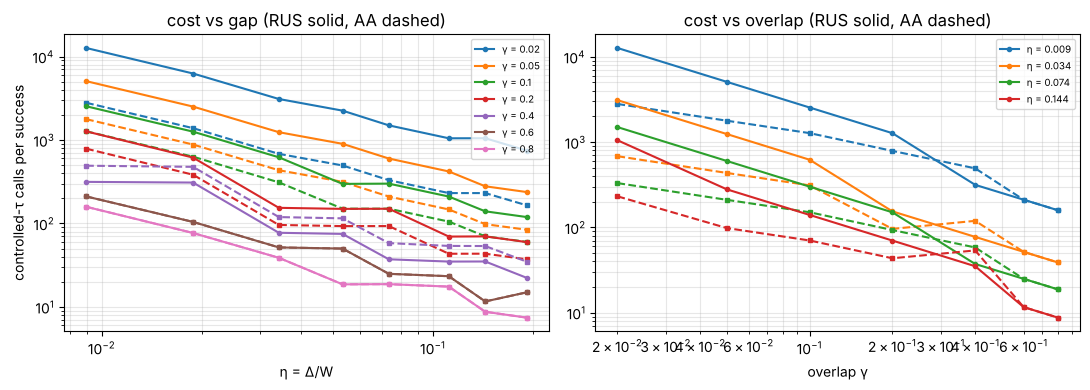

In [13]:
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
# ---- gap vs overlap study: trial = EXACT ground state + staggered Rz (full control of γ), exact evolution
STUDY_DELTAS = [-0.2, -0.15, -0.1, -0.05, 0.0, 0.1, 0.2, 0.4]       # sets η = Δ/W
STUDY_GAMMAS = [0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8]
CNOT_PER_TAU = 6 * ((2 * (2 * N - 3) - 2) * 1 + 1)                    # one Strang step per τ (cell 6 model)

def cheapest(Hs_e, eta_, c):
    # min over (K, r) with 1 - F <= EPS of the cost per success, RUS and AA (τ-calls; AA reflections not counted)
    best = {"RUS": (np.inf,), "AA": (np.inf,)}
    for K_ in range(1, 15):
        f = np.prod([np.cos(2 ** k * np.pi / (1 + eta_) * Hs_e) for k in range(K_)], axis=0)
        fr = np.ones_like(f)
        for r_ in range(1, 11):
            fr = fr * f
            p = np.sum(abs(c * fr) ** 2)
            if p < 1e-300 or 1 - abs(c[0] * fr[0]) ** 2 / p > EPS:
                continue
            d_ = r_ * (2 ** K_ - 1)
            th = np.arcsin(np.sqrt(p)); kk = int(round(np.pi / (4 * th) - 0.5))
            for name, cost in (("RUS", d_ / p), ("AA", (2 * kk + 1) * d_ / np.sin((2 * kk + 1) * th) ** 2)):
                if cost < best[name][0]:
                    best[name] = (cost, K_, r_, p)
            break                                                     # more r at this K only costs more
    return best

rows = []
for dl in STUDY_DELTAS:
    E_, V_ = np.linalg.eigh(hamiltonian(dl))
    W_, eta_ = E_[-1] - E_[0], (E_[1] - E_[0]) / (E_[-1] - E_[0])
    Hs_e, gs = (E_ - E_[0]) / W_, V_[:, 0]
    for gam in STUDY_GAMMAS:
        f = lambda e: abs(np.vdot(gs, np.exp(-1j * e * stag) * gs)) ** 2
        es = np.linspace(0, 1.5, 301); top = es[np.argmax(np.diff([f(e) for e in es]) > 0)]
        e_ = brentq(lambda e: f(e) - gam, 0, top)
        c = V_.conj().T @ (np.exp(-1j * e_ * stag) * gs)
        b = cheapest(Hs_e, eta_, c)
        rows.append(dict(delta=dl, eta=eta_, gamma=gam, eps_knob=e_, K=b["RUS"][1], r=b["RUS"][2], p=b["RUS"][3],
                         tau_calls_RUS=b["RUS"][0], tau_calls_AA=b["AA"][0]))
study = pd.DataFrame(rows)
study["CNOT_RUS"] = study.tau_calls_RUS * CNOT_PER_TAU
study["CNOT_AA"] = study.tau_calls_AA * CNOT_PER_TAU

print(f"N = {N}, target 1 - F <= {EPS}; cost = controlled-τ calls per success (CNOT ≈ × {CNOT_PER_TAU}, 1 Strang step per τ)")
for col in ("tau_calls_RUS", "tau_calls_AA"):
    print(f"\n{col} (rows η, columns γ)")
    display(study.pivot(index="eta", columns="gamma", values=col).round(1))

fits = {}
for col in ("tau_calls_RUS", "tau_calls_AA"):
    Xf = np.column_stack([np.ones(len(study)), -np.log(study.eta), -np.log(study.gamma)])
    coef = np.linalg.lstsq(Xf, np.log(study[col]), rcond=None)[0]
    fits[col] = coef
    print(f"fit {col}: cost ≈ {np.exp(coef[0]):.3g} · η^-{coef[1]:.3f} · γ^-{coef[2]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for gam in STUDY_GAMMAS:
    s = study[study.gamma == gam]
    l, = ax[0].loglog(s.eta, s.tau_calls_RUS, "o-", ms=3, label=f"γ = {gam}")
    ax[0].loglog(s.eta, s.tau_calls_AA, "s--", ms=3, color=l.get_color())
for et in sorted(study.eta.unique())[::2]:
    s = study[study.eta == et]
    l, = ax[1].loglog(s.gamma, s.tau_calls_RUS, "o-", ms=3, label=f"η = {et:.3f}")
    ax[1].loglog(s.gamma, s.tau_calls_AA, "s--", ms=3, color=l.get_color())
ax[0].set(xlabel="η = Δ/W", ylabel="controlled-τ calls per success", title="cost vs gap (RUS solid, AA dashed)")
ax[1].set(xlabel="overlap γ", title="cost vs overlap (RUS solid, AA dashed)")
for a_ in ax:
    a_.grid(alpha=0.3, which="both"); a_.legend(fontsize=7)
fig.tight_layout(); plt.show()